# Figure 2: Performance summary

Three performance measures for the online (OL) task:

- **Panel A: Example session trajectories**: step sequences from one participant from cohort 1, block 2 (coin
  penalty) at the lowest signal-to-noise ratio (SNR). A filled right-pointing triangle marks a right choice, an
  open left-pointing triangle a left choice.

- **Panel B: Congruence per non-decision time (NDT) lag**: for each participant, the fraction of trials on which
  the sign of the pigeon position at that lag before the response matches the choice. The lag with the highest
  congruence is the estimated NDT.

- **Panel C: Accuracy vs. median decision time (DT)**: one point per participant, shaded by that participant's
  maximum congruence from B. Error bars are the interquartile range of the participant's DTs (x) and a 50%
  Clopper–Pearson interval on accuracy (y). The red curve is an ideal-observer speed-accuracy benchmark; black
  diamonds on the axes mark the group medians.

**Data**: OL task, lowest SNR. Panels A and C use block 2 (coin penalty); panel B and the shading in C use each
participant's lowest-SNR trials from all three blocks (the trials `get_bounds` uses to estimate the NDT).

In [1]:
import sys
sys.path.insert(0, '..')  # find pigeon package in parent directory

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats

from pigeon.data import get_data_table
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import (CM, FS_INSET, CONDITION_LABELS, DATA_COLOR, MARKER_SIZE, OPTIMAL_COLOR, add_panel_label,
                             format_p, use_figure_style)

## Load data

All OL (blocked-SNR) trials, `get_data_table(task_type='OL')`, with blocks 4–6 (the same three
conditions at high SNR) relabeled 1–3.

In [2]:
data_table_ol = get_data_table(task_type='OL')

## Compute per-subject summaries

**Trials**: block 2, lowest SNR, `DT > 0`, `trial_number ≥ 10`, no wall hit. This is looser than the standard
filter (`get_good_trial_array`: `DT ≥ 2`, below the RT cutoff), which protects the per-trial bound estimate; this
notebook uses only `DT` and `correct`, never `bound`. Wall-hit trials are still excluded because the wall
inflates their DT.

Per subject: congruence at each NDT lag (from `get_data_table`), accuracy with a 50% Clopper–Pearson interval,
median DT with its interquartile range, and the Spearman correlations of accuracy, median DT and maximum
congruence.

In [3]:
BLOCK = 2          # which block to use for performance summary
EXAMPLE_SESSION = 10  # subject index for the example trajectory panel

subjects = np.sort(data_table_ol['subject_index'].dropna().unique())
n_subjects = len(subjects)
a_snrs = np.abs(data_table_ol['snr'].to_numpy())
min_snr = np.nanmin(a_snrs)

# Select trials from the target block at the lowest SNR (hardest condition)
lg_good = (
    (data_table_ol['DT'] > 0) &
    (data_table_ol['block_index'] == BLOCK) &
    pd.Series(np.isclose(a_snrs, min_snr), index=data_table_ol.index) &
    (data_table_ol['trial_number'] >= 10) &
    (data_table_ol['wall_hit'] == False)
)

# Number of NDT lags reported by get_bounds/get_data_table (max_ndt, default 5).
# Derived from the data rather than hardcoded so this notebook tracks whichever
# value get_data_table is actually called with.
N_NDT = next(arr.shape[0] for arr in data_table_ol['congruence'] if isinstance(arr, np.ndarray))

congruence_summary = np.full((n_subjects, N_NDT), np.nan)  # congruence at each NDT lag (0 .. N_NDT-1)
performance_summary = np.full((n_subjects, 2), np.nan)  # columns: accuracy, median DT
n_correct_summary  = np.full(n_subjects, np.nan)
n_trials_summary   = np.full(n_subjects, np.nan)
dt_ci_summary      = np.full((n_subjects, 2), np.nan)   # [25th, 75th] percentile (IQR) of DT

rng = np.random.default_rng(0)

for si, subj in enumerate(subjects):
    ls = data_table_ol['subject_index'] == subj

    # Pull congruence array stored on the first row of each subject
    first_idx = ls[ls].index[0]
    cong = data_table_ol.loc[first_idx, 'congruence']
    if cong is not None and isinstance(cong, np.ndarray) and cong.ndim == 2 and cong.shape[0] >= N_NDT and cong.shape[1] >= 1:
        congruence_summary[si] = cong[:N_NDT, 0]  # first SNR level, first N_NDT NDT lags

    # Accuracy and median DT for this subject's good trials
    lsg = lg_good & ls
    if lsg.any():
        subset = data_table_ol[lsg]
        n_correct = int(subset['correct'].sum())
        n_trials  = int(subset['correct'].notna().sum())
        dt_vals   = subset['DT'].dropna().values

        performance_summary[si, 0] = n_correct / n_trials
        performance_summary[si, 1] = np.median(dt_vals)
        n_correct_summary[si] = n_correct
        n_trials_summary[si]  = n_trials

        # IQR (25th/75th percentile) of the raw per-trial DT distribution
        if len(dt_vals) > 1:
            dt_ci_summary[si] = np.percentile(dt_vals, [25, 75])

# Clopper-Pearson 50% CI on accuracy (25th/75th percentile of the beta posterior)
acc_lo = np.full(n_subjects, np.nan)
acc_hi = np.full(n_subjects, np.nan)
for si in range(n_subjects):
    if np.isfinite(n_correct_summary[si]):
        k = int(n_correct_summary[si])
        n = int(n_trials_summary[si])
        acc_lo[si] = scipy.stats.beta.ppf(0.25, k,     n - k + 1)
        acc_hi[si] = scipy.stats.beta.ppf(0.75, k + 1, n - k)

# Max congruence per subject (peak over the N_NDT lags) — a proxy for how
# consistently a subject's choice tracked the pigeon's position, i.e. how much
# they were engaging with the evidence vs. guessing.
max_congruence = np.nanmax(congruence_summary, axis=1)

# Spearman correlation between accuracy and median DT
valid = np.isfinite(performance_summary[:, 0]) & np.isfinite(performance_summary[:, 1])
r_spearman, p_spearman = scipy.stats.spearmanr(performance_summary[valid, 0], performance_summary[valid, 1])
print(f'Accuracy = {np.nanpercentile(performance_summary[:,0],50):.2f} '
      f'[{np.nanpercentile(performance_summary[:,0],25):.2f} {np.nanpercentile(performance_summary[:,0],75):.2f}], '
      f'Median DT = {np.nanpercentile(performance_summary[:,1],50):.2f} '
      f'[{np.nanpercentile(performance_summary[:,1],25):.2f} {np.nanpercentile(performance_summary[:,1],75):.2f}]')
print(f'Spearman acc vs DT = {r_spearman:.2f}, {format_p(p_spearman)}')

r_cong_acc, p_cong_acc = scipy.stats.spearmanr(max_congruence[valid], performance_summary[valid, 0])
r_cong_dt,  p_cong_dt  = scipy.stats.spearmanr(max_congruence[valid], performance_summary[valid, 1])
print(f'Max congruence range = [{np.nanmin(max_congruence):.2f}, {np.nanmax(max_congruence):.2f}]')
print(f'Spearman max congruence vs accuracy = {r_cong_acc:.2f}, {format_p(p_cong_acc)}')
print(f'Spearman max congruence vs median DT = {r_cong_dt:.2f}, {format_p(p_cong_dt)}')

Accuracy = 0.76 [0.68 0.81], Median DT = 5.00 [3.00 7.25]
Spearman acc vs DT = 0.67, p<0.001
Max congruence range = [0.50, 0.99]
Spearman max congruence vs accuracy = 0.50, p<0.001
Spearman max congruence vs median DT = 0.55, p<0.001


## Ideal-observer benchmark for panel C

A random walk with the task's low-SNR step statistics (`generative_mean=0.05`, `generative_std=0.15`) that
stops when |position| first reaches a fixed bound, with no NDT, lapses, bound variability or wall. Sweeping the
bound traces the speed-accuracy frontier of fixed-bound strategies at this SNR. Each bound gives a median DT (to
match the participants' median DTs) and an accuracy; because medians are whole steps, the curve is a staircase.
DT here counts steps to the crossing, as `DT` does in the data (RT minus NDT).

In [4]:
def simulate_ideal_observer(bounds, generative_mean=0.05, generative_std=0.15,
                             n_sim=50000, max_steps=1000, rng=None):
    """Simulate a no-NDT, no-wall bound-crossing ideal observer.

    For each candidate bound, runs n_sim independent random walks with per-step
    increments ~ N(generative_mean, generative_std), starting at 0, until
    |position| first reaches the bound. Returns the median crossing step (DT) and
    the fraction of crossings on the correct (positive-drift) side (accuracy).
    """
    if rng is None:
        rng = np.random.default_rng(0)
    median_dt = np.full(len(bounds), np.nan)
    accuracy = np.full(len(bounds), np.nan)
    for bi, b in enumerate(bounds):
        position = np.zeros(n_sim)
        active   = np.ones(n_sim, dtype=bool)
        dt       = np.full(n_sim, np.nan)
        correct  = np.full(n_sim, np.nan)
        for step in range(1, max_steps + 1):
            n_active = int(active.sum())
            if n_active == 0:
                break
            position[active] += rng.normal(generative_mean, generative_std, size=n_active)
            crossed = active & (np.abs(position) >= b)
            if crossed.any():
                dt[crossed]      = step
                correct[crossed] = position[crossed] > 0
                active &= ~crossed
        median_dt[bi] = np.nanmedian(dt)
        accuracy[bi]  = np.nanmean(correct)
    return median_dt, accuracy


ideal_bounds = np.arange(0.02, 0.85, 0.005)
ideal_dt, ideal_acc = simulate_ideal_observer(ideal_bounds, rng=np.random.default_rng(0))
print(f'Ideal observer: bound {ideal_bounds[0]:.2f}-{ideal_bounds[-1]:.2f} -> '
      f'median DT {ideal_dt[0]:.0f}-{ideal_dt[-1]:.0f}, accuracy {ideal_acc[0]:.2f}-{ideal_acc[-1]:.2f}')

Ideal observer: bound 0.02-0.85 -> median DT 1-15, accuracy 0.64-0.98


## Figure

8.5 cm wide (one column), three 4-cm rows 2 cm apart; 12-pt axis and tick labels, 8-pt in-panel text.
Saves `Figure02.pdf` (+ `.png`) to `FIGURES_DIR`.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


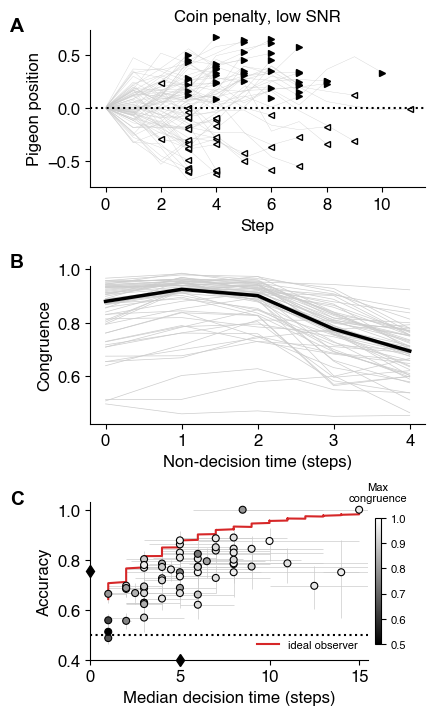

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure02.pdf (+ .png)


In [5]:
from matplotlib.ticker import MaxNLocator
import matplotlib.gridspec as gridspec

WID = 8.5
HTS = [4.0, 4.0, 4.0]
PSH = 2.0

fig_h       = sum(HTS) + PSH * (len(HTS) - 1)   # 16 cm
hspace_frac = PSH / np.mean(HTS)

use_figure_style()
fig = plt.figure(figsize=(WID * CM, fig_h * CM))
gs = gridspec.GridSpec(3, 1, figure=fig,
                       hspace=hspace_frac,
                       left=0, right=1, bottom=0, top=1)
axs = [fig.add_subplot(gs[r]) for r in range(3)]

gr = (0.8, 0.8, 0.8)

# A: example session trajectories (thin light-gray lines so the overlapping traces stay legible). Choice side is
# marker shape and fill, not color, to stay distinct from panel C's grayscale shading.
ax = axs[0]
ls_ex = lg_good & (data_table_ol['subject_index'] == EXAMPLE_SESSION)
example = data_table_ol[ls_ex][['choice', 'steps']]
for _, row in example.iterrows():
    ax.plot(np.arange(len(row['steps'])), row['steps'], '-', color=(0.8, 0.8, 0.8), linewidth=0.25)
for _, row in example.iterrows():
    steps = row['steps']
    x, y = len(steps) - 1, steps[-1]
    if row['choice'] == 1:
        ax.plot(x, y, marker='>', color='k', markerfacecolor='k', markersize=MARKER_SIZE)
    else:
        ax.plot(x, y, marker='<', color='k', markerfacecolor='w', markersize=MARKER_SIZE)
ax.axhline(0, color='k', linestyle=':')
ax.set_xlabel('Step')
ax.set_ylabel('Pigeon position')
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title(f'{CONDITION_LABELS[BLOCK]}, low SNR')

# B: congruence per NDT
# Light-gray per-subject lines with a thick black median.
ax = axs[1]
xax = np.arange(N_NDT)
ax.plot(xax, congruence_summary.T, '-', color=gr, linewidth=0.5)
ax.plot(xax, np.nanmedian(congruence_summary, axis=0), 'k-', linewidth=2.5)
ax.set_xlabel('Non-decision time (steps)')
ax.set_ylabel('Congruence')

# C: accuracy vs. median DT
# x-limit from the data so every subject's median DT is visible. Shading = max congruence over the NDT lags
# (dark = near chance, light = choices consistently follow the pigeon).
ax = axs[2]
ax.axhline(0.5, color='k', linestyle=':')
ax.plot(ideal_dt, ideal_acc, '-', color=OPTIMAL_COLOR, linewidth=1.5, zorder=1.5,
        label='ideal observer')
xerr = np.array([performance_summary[:, 1] - dt_ci_summary[:, 0],
                 dt_ci_summary[:, 1] - performance_summary[:, 1]])
yerr = np.array([performance_summary[:, 0] - acc_lo,
                 acc_hi - performance_summary[:, 0]])
ax.errorbar(performance_summary[:, 1], performance_summary[:, 0],
            xerr=xerr, yerr=yerr,
            fmt='none', ecolor=gr, capsize=0, linewidth=0.5, zorder=1)
sc = ax.scatter(performance_summary[:, 1], performance_summary[:, 0],
                 c=max_congruence, cmap='gray', vmin=0.5, vmax=1.0,
                 edgecolors=DATA_COLOR, linewidths=0.8, s=MARKER_SIZE**2, zorder=2)
ax.plot(0, np.nanmedian(performance_summary[:, 0]), 'd', color=DATA_COLOR, clip_on=False, zorder=3)
ax.plot(np.nanmedian(performance_summary[:, 1]), 0.4, 'd', color=DATA_COLOR, clip_on=False, zorder=3)
dt_xlim_hi = np.ceil(np.nanmax(performance_summary[:, 1])) + 0.5
ax.set_xlim(0, dt_xlim_hi)
ax.set_ylim(0.4, 1.03)
ax.set_xlabel('Median decision time (steps)')
ax.set_ylabel('Accuracy')
ax.legend(loc='lower right', fontsize=FS_INSET, frameon=False)
cbar = fig.colorbar(sc, ax=ax, shrink=0.8, pad=0.02)
# Label above the color scale; pad=12 clears the "1.0" tick at its top.
cbar.ax.set_title('Max\ncongruence', fontsize=FS_INSET, pad=12)
cbar.ax.tick_params(labelsize=FS_INSET)

# Letters sit left of the 12-pt tick labels; panel C is narrowed by its colorbar, so its axes-fraction
# offset is scaled to land at the same distance from the axis as A and B.
PANEL_DX = -0.24
add_panel_label(axs[0], 'A', dx=PANEL_DX)
add_panel_label(axs[1], 'B', dx=PANEL_DX)
add_panel_label(axs[2], 'C', dx=PANEL_DX * axs[0].get_position().width / axs[2].get_position().width)

for ax in axs:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

out = FIGURES_DIR / 'Figure02.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')